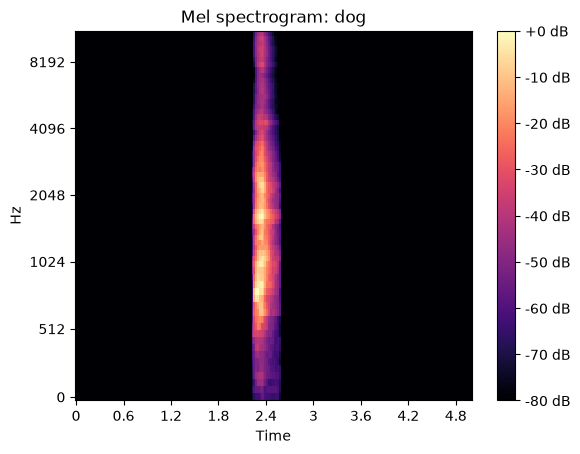

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

path = "../data/train/dog/1-100032-A-0.wav"

audio, sample_rate = librosa.load(path, sr=22050)
mel = librosa.feature.melspectrogram(y=audio, sr=sample_rate, n_mels=64)
mel_db = librosa.power_to_db(mel, ref=np.max)

librosa.display.specshow(mel_db, sr=sample_rate, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel spectrogram: dog")
plt.show()

In [2]:
from pathlib import Path

TRAIN_DIR = Path("../data/train")
SAMPLE_RATE = 22050


def first_clip(class_name):
    return sorted((TRAIN_DIR / class_name).glob("*.wav"))[0]


def make_mel_db(path):
    audio, sr = librosa.load(path, sr=SAMPLE_RATE)
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=64)
    return librosa.power_to_db(mel, ref=np.max)

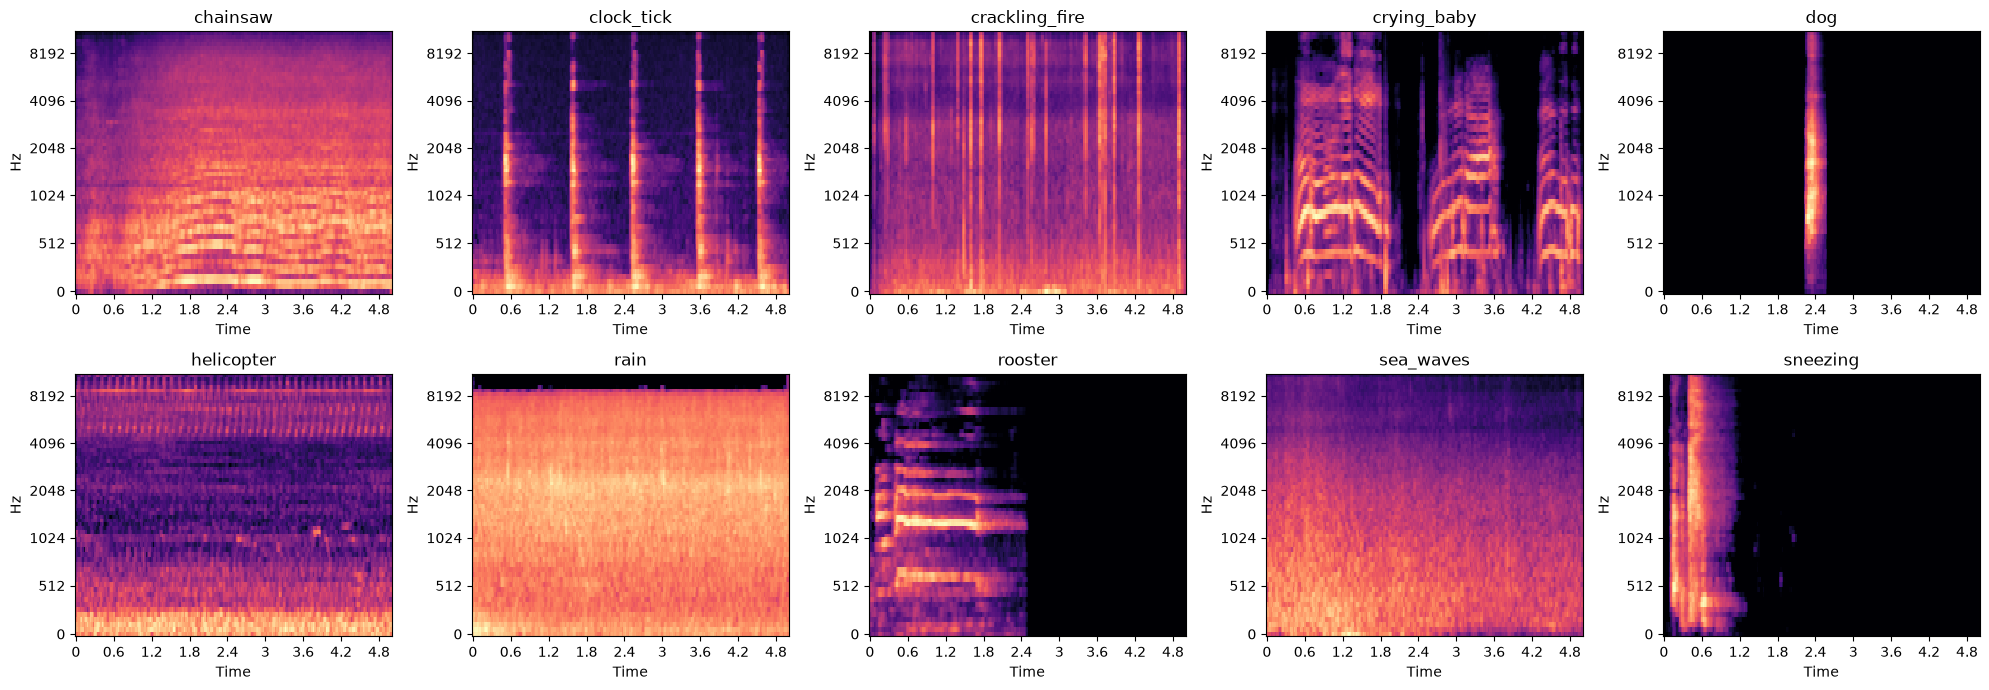

In [3]:
class_names = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())

fig, axes = plt.subplots(2, 5, figsize=(20, 7))

for ax, name in zip(axes.flatten(), class_names):
    mel_db = make_mel_db(first_clip(name))
    librosa.display.specshow(mel_db, sr=SAMPLE_RATE, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [4]:
import pandas as pd

def clip_features(path):
    audio, sr = librosa.load(path, sr=SAMPLE_RATE)
    rms = librosa.feature.rms(y=audio).mean()
    centroid = librosa.feature.spectral_centroid(y=audio, sr=sr).mean()
    return rms, centroid


def build_feature_table():
    rows = []
    for class_name in class_names:
        for path in (TRAIN_DIR / class_name).glob("*.wav"):
            rms, centroid = clip_features(path)
            rows.append({"class": class_name, "rms": rms, "centroid": centroid})
    return pd.DataFrame(rows)


features = build_feature_table()
features.head()

,class,rms,centroid
0,chainsaw,0.109519,3470.513428
1,chainsaw,0.269410,2226.115967
2,chainsaw,0.215510,4240.780762
3,chainsaw,0.060397,3723.200928
4,chainsaw,0.236111,3635.996338


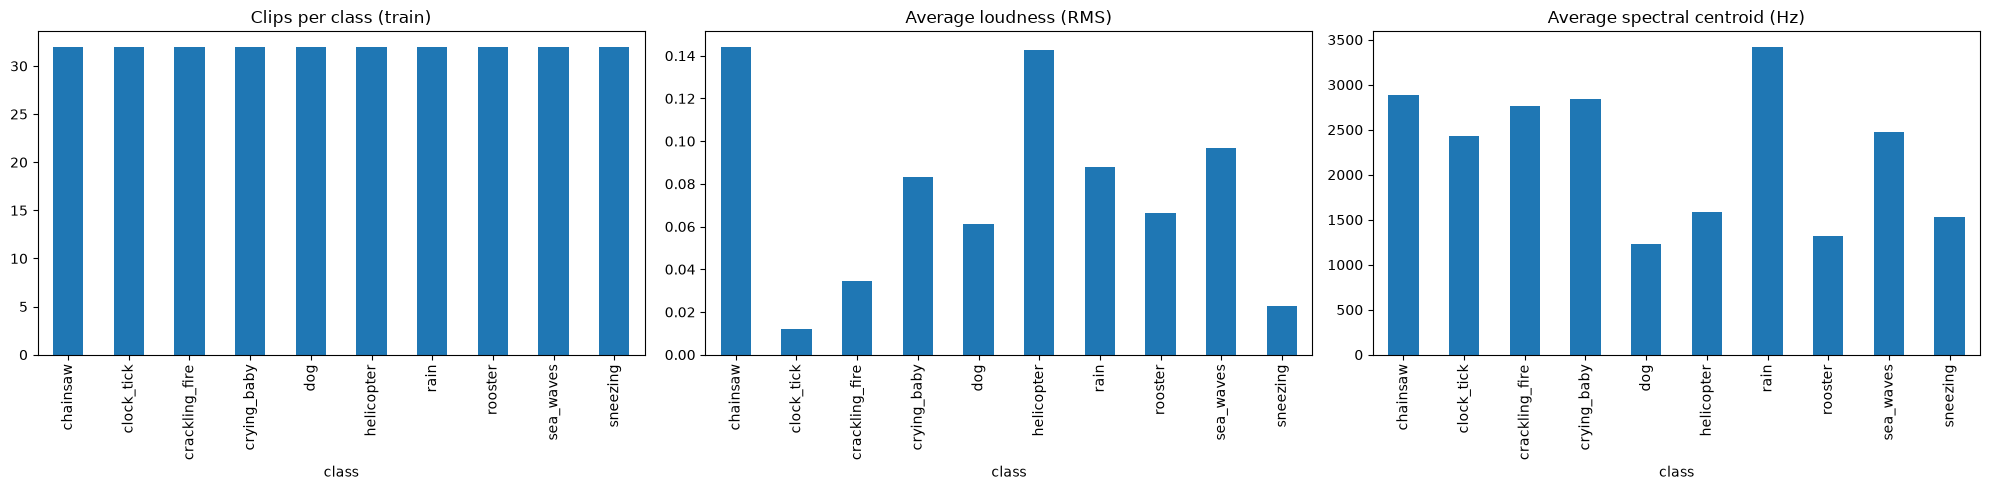

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

features["class"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Clips per class (train)")

features.groupby("class")["rms"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Average loudness (RMS)")

features.groupby("class")["centroid"].mean().plot(kind="bar", ax=axes[2])
axes[2].set_title("Average spectral centroid (Hz)")

plt.tight_layout()
plt.show()

## Feature interpretations

**1. Class balance.** Every class has exactly 32 training clips, so the dataset is perfectly balanced. No class can dominate the training, which means accuracy is a fair metric here.


**2. Loudness (RMS).** Chainsaw and helicopter are by far the loudest classes, while clock tick, sneezing and crackling fire are the quietest. Loudness alone separates the very loud engines from the very quiet sounds, but it cannot tell apart the classes in the middle (such as dog, rooster and rain).

**3. Spectral centroid (brightness).** Rain has the highest centroid because its energy is spread across high frequencies like hiss. Dog and rooster have the lowest, because most of their energy sits in lower frequencies. Helicopter and chainsaw have similar loudness but very different brightness (about 1600 Hz vs 2900 Hz), so the two features together separate them well.

 No single feature identifies every class, but loudness and brightness together place most classes in different regions. Rain and sea waves
 look alike in the spectrograms, so the model will probably confuse them more than other pairs.